# Expérience — Ensemble de trois modèles : Lasso, Kernel Ridge et XGBoost

L'[expérience 04](04_ensemble.ipynb) combinait cinq modèles. Sa matrice de corrélation des erreurs hors pli (section 5.1) montrait deux familles :

| | Lasso | ElasticNet | Kernel Ridge | Gradient Boosting | XGBoost |
|---|---|---|---|---|---|
| **Lasso** | 1,00 | 1,00 | 0,97 | 0,83 | 0,83 |
| **ElasticNet** | 1,00 | 1,00 | 0,98 | 0,84 | 0,84 |
| **Kernel Ridge** | 0,97 | 0,98 | 1,00 | 0,85 | 0,85 |
| **Gradient Boosting** | 0,83 | 0,84 | 0,85 | 1,00 | 0,92 |
| **XGBoost** | 0,83 | 0,84 | 0,85 | 0,92 | 1,00 |

Lasso, ElasticNet et Kernel Ridge se trompent presque sur les mêmes maisons. Dans une moyenne simple, ces trois modèles linéaires comptent pour 3/5 du poids, alors qu'ils apportent presque la même information.

**Hypothèse.** Une moyenne de trois modèles moins redondants, Lasso, Kernel Ridge et XGBoost, ferait aussi bien que la moyenne des cinq, avec deux modèles de moins. Lasso représente les modèles linéaires simples (ElasticNet fait les mêmes erreurs). Kernel Ridge ajoute les interactions entre variables. XGBoost représente les arbres (Gradient Boosting est corrélé à 0,92 avec lui).

**Protocole.** Tout est repris de l'expérience 04 sans changement : même partition (80 % / 20 %, graine 42), mêmes plis de validation croisée, même prétraitement (recette de l'expérience), mêmes hyperparamètres, mêmes deux ventes atypiques retirées de l'entraînement, même métrique (RMSE des logarithmes, sur les ventes typiques). Seule la liste des modèles moyennés change.

Une moyenne simple n'apprend aucun paramètre. La moyenne de trois modèles se calcule donc directement à partir des prédictions hors pli des cinq modèles, sans réentraîner : les deux ensembles sont comparés sur exactement les mêmes prédictions.

### Résultats de l'expérience 04

| Méthode | RMSE log, validation croisée (ventes typiques) | RMSE log, validation (292 maisons) |
|---|---|---|
| Moyenne simple des cinq modèles | 0,1067 | 0,1233 |
| Kernel Ridge, meilleur modèle seul | 0,1104 | 0,1247 |

## 1. Configuration

In [1]:
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ElasticNetCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from xgboost import XGBRegressor

# Repérer la racine depuis le dossier courant ou l'un de ses parents.
current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "pyproject.toml").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt MAP6014.")
data_dir = root / "data"

# Mêmes réglages que l'expérience 04
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20
N_FOLDS = 5
SKEW_THRESHOLD = 0.75
MIN_CATEGORY_COUNT = 5

FIVE = ["Lasso", "ElasticNet", "Kernel Ridge", "Gradient Boosting", "XGBoost"]
THREE = ["Lasso", "Kernel Ridge", "XGBoost"]
ENSEMBLES = {"Moyenne des cinq (exp. 04)": FIVE, "Moyenne des trois": THREE}

# LassoCV et ElasticNetCV testent de très faibles pénalités, qui convergent lentement;
# ces combinaisons ne sont jamais retenues. Leurs avertissements sont masqués.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

## 2. Données et prétraitement

Le code de cette section reprend celui des sections 2 et 3 de l'expérience 04, sans changement. Il est regroupé ici sans les figures; les explications sont dans l'expérience 04.

In [2]:
# =======================================================================
# Partition (expérience 04, section 2)
# =======================================================================
read_options = {"na_values": ["NA"], "keep_default_na": False}
train_full = pd.read_csv(data_dir / "train.csv", **read_options)
train_part, valid_part = train_test_split(
    train_full, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE
)
train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)
y_train = np.log(train_part["SalePrice"])
y_valid = np.log(valid_part["SalePrice"])

# =======================================================================
# Ventes atypiques (expérience 04, section 3.1)
# =======================================================================
def atypical_mask(frame):
    return (frame["GrLivArea"].gt(4000) & frame["SalePrice"].lt(300_000)).to_numpy()


atypical = atypical_mask(train_part)
typical = ~atypical
keep_all = np.ones(len(train_part), dtype=bool)

# =======================================================================
# Corrections, variables calculées et encodage ordinal (expérience 04, section 3.2)
# =======================================================================
ABSENCE_COLUMNS = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]
ABSENCE_NUMERIC = [
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
    "GarageCars", "GarageArea", "MasVnrArea",
]
EXTERIOR2_FIXES = {"Wd Shng": "WdShing", "CmentBd": "CemntBd", "Brk Cmn": "BrkComm"}
QUALITY_SCALE = {"Aucun": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUALITY_COLUMNS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]
FAKE_NUMERIC = ["MSSubClass", "MoSold", "YrSold"]
PORCH_COLUMNS = ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]


def prepare_features(frame):
    X = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    X[ABSENCE_COLUMNS] = X[ABSENCE_COLUMNS].fillna("Aucun")
    X[ABSENCE_NUMERIC] = X[ABSENCE_NUMERIC].fillna(0)
    X.loc[X["GarageYrBlt"].gt(X["YrSold"]), "GarageYrBlt"] = np.nan
    X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])
    X["Exterior2nd"] = X["Exterior2nd"].replace(EXTERIOR2_FIXES)

    X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
    X["TotalBath"] = (X["FullBath"] + 0.5 * X["HalfBath"]
                      + X["BsmtFullBath"] + 0.5 * X["BsmtHalfBath"])
    X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    X["RemodAge"] = X["YrSold"] - X["YearRemodAdd"]
    X["TotalPorchSF"] = X[PORCH_COLUMNS].sum(axis=1)
    X["HasPool"] = X["PoolArea"].gt(0).astype(int)
    X["HasGarage"] = X["GarageArea"].gt(0).astype(int)
    X["Has2ndFlr"] = X["2ndFlrSF"].gt(0).astype(int)

    X[QUALITY_COLUMNS] = X[QUALITY_COLUMNS].apply(lambda column: column.map(QUALITY_SCALE))
    X[FAKE_NUMERIC] = X[FAKE_NUMERIC].astype(str)
    return X


X_train = prepare_features(train_part)
X_valid = prepare_features(valid_part)
categorical_columns = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_columns = [c for c in X_train.columns if c not in categorical_columns]

# =======================================================================
# Asymétrie et pipeline de prétraitement (expérience 04, sections 3.3 et 3.4)
# =======================================================================
class SkewedLog1p(BaseEstimator, TransformerMixin):
    # Appliquer log1p aux colonnes positives dont l'asymétrie apprise dépasse le seuil.

    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)  # colonnes presque constantes
            self.skewness_ = skew(X, axis=0)
        eligible = ((self.skewness_ > self.threshold) & (X.min(axis=0) >= 0)
                    & ((X == 0).mean(axis=0) < 1.0))
        self.columns_ = np.flatnonzero(eligible)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        X[:, self.columns_] = np.log1p(np.clip(X[:, self.columns_], 0, None))
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def make_preprocessor():
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("skew", SkewedLog1p(SKEW_THRESHOLD)),
        ("scale", RobustScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=MIN_CATEGORY_COUNT, sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", numeric_steps, numeric_columns), ("cat", categorical_steps, categorical_columns)],
        verbose_feature_names_out=False,
    )


print(f"Entraînement : {len(train_part)} maisons (ventes atypiques : "
      f"{train_part.loc[atypical, 'Id'].tolist()}), validation : {len(valid_part)} maisons.")

Entraînement : 1168 maisons (ventes atypiques : [524, 1299]), validation : 292 maisons.


## 3. Prédictions hors pli des cinq modèles

Les cinq modèles de l'expérience 04 sont réentraînés sur les mêmes plis, avec les mêmes hyperparamètres. Le tableau doit retrouver les scores de l'expérience 04 (section 4.2), ce qui confirme que les deux expériences sont comparables.

In [3]:
MODELS = {
    "Lasso": LassoCV(alphas=np.logspace(-4.5, -1.5, 40), max_iter=50_000, n_jobs=-1),
    "ElasticNet": ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
                               alphas=np.logspace(-4.5, -1.5, 40), max_iter=50_000, n_jobs=-1),
    "Kernel Ridge": KernelRidge(alpha=0.6, kernel="polynomial", degree=2, coef0=2.5),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=3000, learning_rate=0.05, max_depth=4, max_features="sqrt",
        min_samples_leaf=15, min_samples_split=10, loss="huber", random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=2000, learning_rate=0.02, max_depth=4, min_child_weight=2,
        subsample=0.7, colsample_bytree=0.5, reg_lambda=1.0,
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    ),
}


def make_model(name):
    return Pipeline([("prep", make_preprocessor()), ("model", clone(MODELS[name]))])


cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_id = np.empty(len(X_train), dtype=int)
for k, (_, eval_index) in enumerate(cv.split(X_train)):
    fold_id[eval_index] = k


def out_of_fold(name):
    # Prédictions hors pli; les ventes atypiques sont exclues de l'entraînement seulement.
    oof = np.empty(len(X_train))
    for fit_index, eval_index in cv.split(X_train):
        fit_index = fit_index[~atypical[fit_index]]
        model = make_model(name).fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        oof[eval_index] = model.predict(X_train.iloc[eval_index])
    return oof


def fold_scores(prediction, mask=typical):
    # RMSE log de chaque pli, calculée sur les maisons de mask (par défaut : ventes typiques).
    return np.array([rmse(y_train[(fold_id == k) & mask], prediction[(fold_id == k) & mask])
                     for k in range(N_FOLDS)])


oof = pd.DataFrame({name: out_of_fold(name) for name in FIVE})
for label, members in ENSEMBLES.items():
    oof[label] = oof[members].mean(axis=1)

cv_summary = pd.DataFrame({
    name: {"RMSE log (moyenne des plis)": fold_scores(oof[name]).mean(),
           "Écart type entre plis": fold_scores(oof[name]).std(),
           "RMSE log, toutes les ventes": fold_scores(oof[name], keep_all).mean()}
    for name in oof
}).T.sort_values("RMSE log (moyenne des plis)")
display(cv_summary.round(4))

,RMSE log (moyenne des plis),Écart type entre plis,"RMSE log, toutes les ventes"
Moyenne des cinq (exp. 04),0.1067,0.0106,0.1248
Moyenne des trois,0.1074,0.0107,0.1266
Kernel Ridge,0.1104,0.0091,0.1351
ElasticNet,0.1112,0.0085,0.1339
Lasso,0.1117,0.0082,0.1347
Gradient Boosting,0.1122,0.0119,0.1220
XGBoost,0.1136,0.0131,0.1236


**Interprétation.** Les cinq modèles retrouvent exactement leurs scores de l'expérience 04 (Kernel Ridge 0,1104, Lasso 0,1117, XGBoost 0,1136…), et la moyenne des cinq retrouve 0,1067 : les deux expériences sont bien comparables.

La **moyenne des trois** obtient **0,1074**. Elle fait mieux que chacun de ses membres (0,1104 pour Kernel Ridge, le meilleur), mais **un peu moins bien que la moyenne des cinq** (0,1067), soit un écart de 0,0007. Sur toutes les ventes, l'écart est un peu plus grand (0,1266 contre 0,1248).

## 4. Comparaison des deux ensembles

### 4.1 Pli par pli

Les écarts entre modèles sont de l'ordre du millième, plus petits que l'écart type entre plis. Comparer les deux ensembles **dans chaque pli** dit si l'écart est régulier ou s'il vient d'un seul pli.

In [4]:
per_fold = pd.DataFrame({label: fold_scores(oof[label]) for label in ENSEMBLES},
                        index=[f"Pli {k + 1}" for k in range(N_FOLDS)])
per_fold["Écart (trois − cinq)"] = per_fold["Moyenne des trois"] - per_fold["Moyenne des cinq (exp. 04)"]
display(per_fold.round(4))

,Moyenne des cinq (exp. 04),Moyenne des trois,Écart (trois − cinq)
Pli 1,0.1192,0.1196,0.0004
Pli 2,0.1017,0.1019,0.0002
Pli 3,0.1198,0.1211,0.0013
Pli 4,0.0969,0.0977,0.0008
Pli 5,0.0959,0.0965,0.0007


**Interprétation.** La moyenne des cinq fait mieux **dans chacun des cinq plis**, de 0,0002 à 0,0013. L'écart est petit, bien plus petit que l'écart type entre plis (environ 0,01), mais il est régulier : ce n'est pas un pli particulier qui le produit.

### 4.2 Erreur moyenne des modèles et désaccord

Pour une moyenne de $k$ modèles et une erreur mesurée au carré, l'erreur de la moyenne est égale à l'erreur moyenne des modèles, moins leur désaccord (décomposition de l'ambiguïté, Krogh et Vedelsby, 1995) :

$$
\underbrace{(\bar{p} - y)^2}_{\text{erreur de la moyenne}}
= \underbrace{\frac{1}{k}\sum_{i=1}^{k} (p_i - y)^2}_{\text{erreur moyenne des modèles}}
- \underbrace{\frac{1}{k}\sum_{i=1}^{k} (p_i - \bar{p})^2}_{\text{désaccord entre les modèles}}
$$

où $y$ est le logarithme du prix réel, $p_i$ la prédiction du modèle $i$ et $\bar{p}$ leur moyenne. Retirer ElasticNet et Gradient Boosting change les deux termes : l'erreur moyenne des modèles, et leur désaccord. Le tableau donne la moyenne de chaque terme sur les ventes typiques (erreurs au carré, échelle logarithmique).

,Erreur moyenne des modèles,Désaccord entre les modèles,Erreur de la moyenne,Part de l'erreur retirée
Moyenne des cinq (exp. 04),0.01261,0.00111,0.01150,8.8%
Moyenne des trois,0.01263,0.00099,0.01164,7.8%


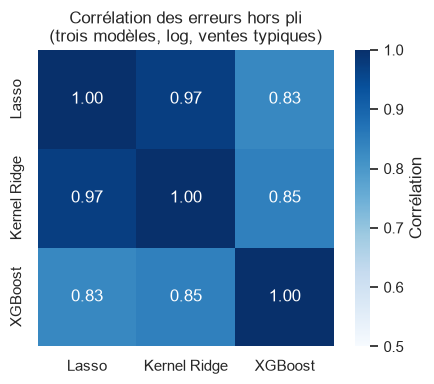

In [5]:
decomposition = {}
for label, members in ENSEMBLES.items():
    predictions = oof.loc[typical, members].to_numpy()
    target = y_train[typical].to_numpy()[:, None]
    mean_prediction = predictions.mean(axis=1, keepdims=True)
    decomposition[label] = {
        "Erreur moyenne des modèles": np.mean((predictions - target) ** 2),
        "Désaccord entre les modèles": np.mean((predictions - mean_prediction) ** 2),
        "Erreur de la moyenne": np.mean((mean_prediction - target) ** 2),
    }
decomposition = pd.DataFrame(decomposition).T
decomposition["Part de l'erreur retirée"] = (decomposition["Désaccord entre les modèles"]
                                            / decomposition["Erreur moyenne des modèles"])
display(decomposition.style.format("{:.5f}").format("{:.1%}", subset=["Part de l'erreur retirée"]))

errors = oof[THREE].sub(y_train.to_numpy(), axis=0)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(errors[typical].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0.5, vmax=1,
            square=True, cbar_kws={"label": "Corrélation"}, ax=ax)
ax.set_title("Corrélation des erreurs hors pli\n(trois modèles, log, ventes typiques)")
plt.tight_layout()
plt.show()

**Interprétation.** L'erreur moyenne des modèles est presque la même dans les deux ensembles (0,01263 contre 0,01261) : retirer ElasticNet et Gradient Boosting ne retire pas des modèles moins bons que les autres. La différence vient du **désaccord**, qui baisse de 0,00111 à 0,00099. La moyenne des trois retire 7,8 % de l'erreur moyenne de ses modèles, contre 8,8 % pour la moyenne des cinq.

L'hypothèse de départ ne se vérifie donc pas. Retirer ElasticNet supprime bien un modèle redondant : sa corrélation avec Lasso est de 1,00, et il n'apportait presque aucun désaccord. Mais retirer Gradient Boosting enlève un des deux modèles d'arbres. Les modèles linéaires passent de 3/5 à 2/3 du poids, et la famille des arbres, celle qui se trompe sur d'autres maisons (corrélation de 0,83 à 0,85 avec les modèles linéaires), pèse moins dans la moyenne.

### 4.3 Toutes les combinaisons des cinq modèles

Les trois modèles retenus sont-ils un bon choix parmi tous les sous-ensembles possibles? Le tableau donne la RMSE log hors pli de la moyenne simple de chaque combinaison d'au moins deux modèles (26 combinaisons), toujours à partir des mêmes prédictions hors pli.

**Prudence.** Choisir la meilleure de 26 combinaisons d'après ces mêmes scores serait optimiste : avec des écarts de l'ordre du millième, la première place peut venir du hasard des plis. Le tableau sert à situer la combinaison choisie d'avance, pas à en choisir une nouvelle.

In [6]:
rows = []
for size in range(2, len(FIVE) + 1):
    for members in combinations(FIVE, size):
        scores = fold_scores(oof[list(members)].mean(axis=1))
        rows.append({"Modèles": " + ".join(members), "Nombre": size,
                     "RMSE log (moyenne des plis)": scores.mean(),
                     "Écart type entre plis": scores.std()})
all_combinations = (pd.DataFrame(rows).sort_values("RMSE log (moyenne des plis)")
                    .reset_index(drop=True))
all_combinations.index += 1
all_combinations.index.name = "Rang"
three_label = " + ".join(THREE)
five_label = " + ".join(FIVE)
print(f"Rang de la moyenne des trois : "
      f"{all_combinations.index[all_combinations['Modèles'] == three_label][0]} sur {len(all_combinations)}")
print(f"Rang de la moyenne des cinq : "
      f"{all_combinations.index[all_combinations['Modèles'] == five_label][0]} sur {len(all_combinations)}")
display(all_combinations.head(10).round(4))

Rang de la moyenne des trois : 14 sur 26
Rang de la moyenne des cinq : 3 sur 26


,Modèles,Nombre,RMSE log (moyenne des plis),Écart type entre plis
Rang,,,,
1,ElasticNet + Kernel Ridge + Gradient Boosting ...,4,0.1065,0.0111
2,Lasso + Kernel Ridge + Gradient Boosting + XGB...,4,0.1065,0.0111
3,Lasso + ElasticNet + Kernel Ridge + Gradient B...,5,0.1067,0.0106
4,Lasso + ElasticNet + Gradient Boosting + XGBoost,4,0.1067,0.0109
5,Kernel Ridge + Gradient Boosting,2,0.1070,0.0106
6,ElasticNet + Kernel Ridge + Gradient Boosting,3,0.1070,0.0101
7,Lasso + Kernel Ridge + Gradient Boosting,3,0.1070,0.0100
8,ElasticNet + Gradient Boosting,2,0.1070,0.0105
9,ElasticNet + Gradient Boosting + XGBoost,3,0.1070,0.0116


**Interprétation.** La moyenne des trois est au **14ᵉ rang sur 26**; la moyenne des cinq est au 3ᵉ. Les dix meilleures combinaisons contiennent **toutes Gradient Boosting**, avec au moins un modèle linéaire. Kernel Ridge et Gradient Boosting seuls (0,1070) font déjà mieux que Lasso, Kernel Ridge et XGBoost (0,1074).

Gradient Boosting est donc le modèle d'arbres le plus utile ici, plus que XGBoost : son score seul est meilleur (0,1122 contre 0,1136), et sa perte de Huber le rend moins sensible aux prix extrêmes.

Les écarts entre les dix premières combinaisons (0,1065 à 0,1071) restent toutefois de l'ordre du millième. Le tableau montre surtout qu'il faut **un modèle linéaire et un modèle d'arbres**, sans permettre de désigner un sous-ensemble nettement meilleur que les autres.

## 5. Évaluation sur la validation

Comme dans l'expérience 04 (section 6), les modèles sont réentraînés sur les 1 168 maisons d'entraînement, sans les deux ventes atypiques, puis évalués **une seule fois** sur les 292 maisons de validation.

In [7]:
def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "RMSE log": np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2)),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }


valid_log = pd.DataFrame(index=valid_part.index)
for name in FIVE:
    model = make_model(name).fit(X_train[typical], y_train[typical])
    valid_log[name] = model.predict(X_valid)
for label, members in ENSEMBLES.items():
    valid_log[label] = valid_log[members].mean(axis=1)

results = pd.DataFrame({
    name: regression_metrics(valid_part["SalePrice"], np.exp(valid_log[name]))
    for name in valid_log
}).T.sort_values("RMSE log")
results.insert(0, "RMSE log (validation croisée)", cv_summary["RMSE log (moyenne des plis)"])
display(results.style.format({
    "RMSE log (validation croisée)": "{:.4f}", "RMSE log": "{:.4f}", "RMSE ($)": "{:,.0f}",
    "MAE ($)": "{:,.0f}", "R²": "{:.3f}",
}))

,RMSE log (validation croisée),RMSE log,RMSE ($),MAE ($),R²
Moyenne des trois,0.1074,0.1222,"22,804","13,752",0.932
Moyenne des cinq (exp. 04),0.1067,0.1233,"22,734","13,682",0.933
Kernel Ridge,0.1104,0.1247,"22,920","14,646",0.932
XGBoost,0.1136,0.1257,"23,937","14,058",0.925
Lasso,0.1117,0.1264,"23,950","14,893",0.925
ElasticNet,0.1112,0.1276,"24,200","15,001",0.924
Gradient Boosting,0.1122,0.1322,"23,273","14,131",0.929


**Interprétation.** Sur les 292 maisons de validation, l'ordre s'inverse : la moyenne des trois obtient **0,1222**, contre 0,1233 pour la moyenne des cinq. Cet écart vient surtout de Gradient Boosting, le moins bon modèle seul en validation (0,1322), qui ne fait plus partie de la moyenne. En dollars, les deux ensembles sont presque identiques (MAE de 13 752 \$ contre 13 682 \$, R² de 0,932 contre 0,933).

Avec 292 maisons, un écart de 0,001 reste dans la marge d'incertitude, comme le notait l'expérience 04. La validation croisée, mesurée sur 1 166 maisons et cohérente dans les cinq plis, est le critère de choix fixé d'avance; la validation ne sert qu'à vérifier que le modèle retenu ne se dégrade pas.

## 6. Conclusion

- **Résultat.** La moyenne de Lasso, Kernel Ridge et XGBoost obtient 0,1074 en validation croisée, contre 0,1067 pour la moyenne des cinq modèles de l'expérience 04. Elle fait un peu moins bien dans chacun des cinq plis. En validation, l'ordre s'inverse (0,1222 contre 0,1233), mais cet écart est dans la marge d'incertitude.
- **Pourquoi.** Retirer ElasticNet ne coûte rien : il fait les mêmes erreurs que Lasso. Retirer Gradient Boosting coûte un peu : c'est le modèle d'arbres le plus utile à l'ensemble, et le désaccord entre les modèles baisse sans lui.
- **Ce que montre la matrice de corrélation.** Elle indique quels modèles sont redondants **à l'intérieur d'une famille**, mais le gain de la moyenne dépend surtout de l'équilibre **entre les familles**. Des erreurs corrélées entre modèles linéaires ne justifient pas, à elles seules, de retirer un modèle d'arbres.
- **Choix.** Avec trois modèles au lieu de cinq, l'ensemble est plus simple à expliquer pour une perte de 0,0007 en validation croisée, plus petite que l'écart type entre plis. Si l'on veut moins de modèles sans perte, le tableau de la section 4.3 suggère plutôt de remplacer XGBoost par Gradient Boosting (Lasso, Kernel Ridge et Gradient Boosting : 0,1070).